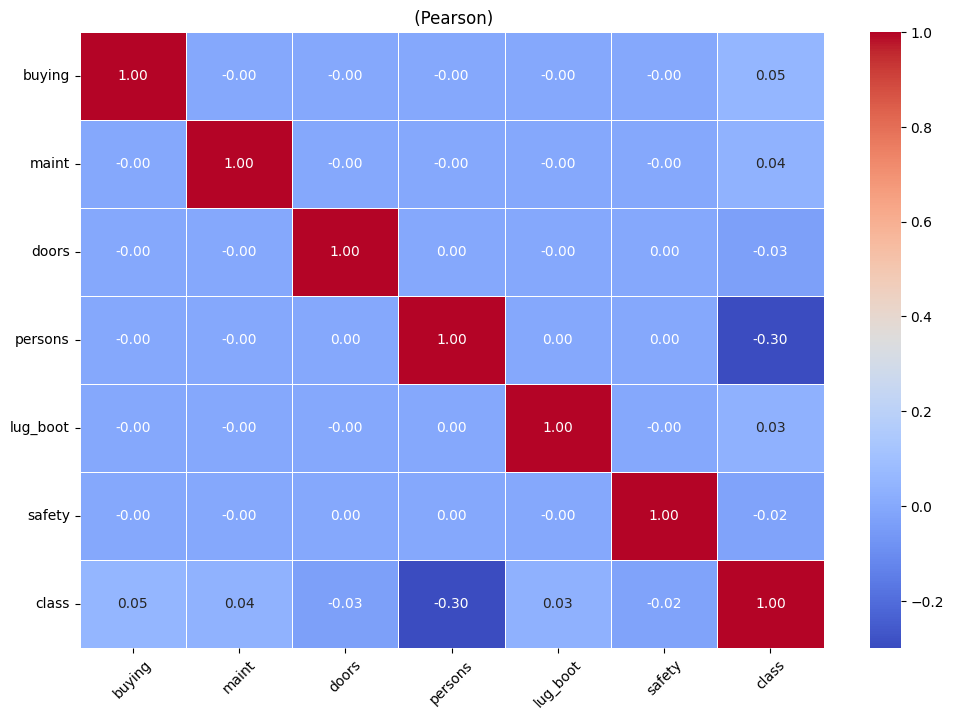

NameError: name 'np' is not defined

<Figure size 1200x800 with 0 Axes>

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from lightgbm import LGBMClassifier
import shap
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay
import seaborn as sns
from scipy.stats import chi2_contingency

# 读取数据
column_names = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
data = pd.read_csv('car.data', names=column_names, sep=',')

plt.show()
# 对所有特征和目标变量进行标签编码
label_encoders = {}
for col in data.columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# 特征相关性分析
plt.figure(figsize=(12, 8))
corr_matrix = data.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title(" (Pearson)")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

# 卡方独立性检验矩阵
p_matrix = pd.DataFrame(index=data.columns, columns=data.columns)
for i in data.columns:
    for j in data.columns:
        if i != j:
            _, p, _, _ = chi2_contingency(pd.crosstab(data[i], data[j]))
            p_matrix.loc[i, j] = p
        else:
            p_matrix.loc[i, j] = 1.0


# 提取特征和目标变量
X = data.drop('class', axis=1)
y = data['class']

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 处理数据不平衡问题（过采样）
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# 逻辑回归模型
logreg = LogisticRegression(random_state=42)
logreg.fit(X_train_resampled, y_train_resampled)
y_pred_logreg = logreg.predict(X_test)
print("逻辑回归模型准确率:", accuracy_score(y_test, y_pred_logreg))
print("逻辑回归模型分类报告:\n", classification_report(y_test, y_pred_logreg))

# 读取数据
column_names = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
data = pd.read_csv('car.data', names=column_names, sep=',')

# 类别特征分布可视化
plt.figure(figsize=(15, 10))
for i, col in enumerate(column_names[:-1], 1):  # 排除class列
    plt.subplot(2, 3, i)
    sns.countplot(data=data, x=col, order=data[col].value_counts().index)
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 对所有特征和目标变量进行标签编码
label_encoders = {}
for col in data.columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

逻辑回归模型准确率: 0.5173410404624278
逻辑回归模型分类报告:
               precision    recall  f1-score   support

           0       0.24      0.14      0.18        83
           1       0.06      0.36      0.10        11
           2       0.83      0.63      0.71       235
           3       0.31      0.94      0.47        17

    accuracy                           0.52       346
   macro avg       0.36      0.52      0.37       346
weighted avg       0.64      0.52      0.55       346



In [3]:
# SVM模型
svm = SVC(random_state=42)
svm.fit(X_train_resampled, y_train_resampled)
y_pred_svm = svm.predict(X_test)
print("SVM模型准确率:", accuracy_score(y_test, y_pred_svm))
print("SVM模型分类报告:\n", classification_report(y_test, y_pred_svm))

# 决策树模型
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train_resampled, y_train_resampled)
y_pred_dtree = dtree.predict(X_test)
print("决策树模型准确率:", accuracy_score(y_test, y_pred_dtree))
print("决策树模型分类报告:\n", classification_report(y_test, y_pred_dtree))

SVM模型准确率: 0.930635838150289
SVM模型分类报告:
               precision    recall  f1-score   support

           0       0.90      0.83      0.86        83
           1       0.42      1.00      0.59        11
           2       1.00      0.97      0.98       235
           3       1.00      0.82      0.90        17

    accuracy                           0.93       346
   macro avg       0.83      0.91      0.84       346
weighted avg       0.95      0.93      0.94       346

决策树模型准确率: 0.9797687861271677
决策树模型分类报告:
               precision    recall  f1-score   support

           0       0.97      0.94      0.96        83
           1       0.73      1.00      0.85        11
           2       1.00      1.00      1.00       235
           3       1.00      0.94      0.97        17

    accuracy                           0.98       346
   macro avg       0.93      0.97      0.94       346
weighted avg       0.98      0.98      0.98       346



In [4]:
# 随机森林模型
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_resampled, y_train_resampled)
y_pred_rf = rf.predict(X_test)
print("随机森林模型准确率:", accuracy_score(y_test, y_pred_rf))
print("随机森林模型分类报告:\n", classification_report(y_test, y_pred_rf))

随机森林模型准确率: 0.9624277456647399
随机森林模型分类报告:
               precision    recall  f1-score   support

           0       0.97      0.87      0.92        83
           1       0.48      0.91      0.62        11
           2       1.00      1.00      1.00       235
           3       1.00      0.94      0.97        17

    accuracy                           0.96       346
   macro avg       0.86      0.93      0.88       346
weighted avg       0.98      0.96      0.97       346



In [5]:
# 朴素贝叶斯模型
nb = GaussianNB()
nb.fit(X_train_resampled, y_train_resampled)
y_pred_nb = nb.predict(X_test)
print("朴素贝叶斯模型准确率:", accuracy_score(y_test, y_pred_nb))
print("朴素贝叶斯模型分类报告:\n", classification_report(y_test, y_pred_nb))

朴素贝叶斯模型准确率: 0.49421965317919075
朴素贝叶斯模型分类报告:
               precision    recall  f1-score   support

           0       0.35      0.31      0.33        83
           1       0.19      0.55      0.29        11
           2       0.96      0.52      0.67       235
           3       0.15      1.00      0.26        17

    accuracy                           0.49       346
   macro avg       0.41      0.59      0.39       346
weighted avg       0.75      0.49      0.56       346



In [6]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, classification_report

# XGBoost模型
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train_resampled, y_train_resampled)
y_pred_xgb = xgb_model.predict(X_test)
print("XGBoost模型准确率:", accuracy_score(y_test, y_pred_xgb))
print("XGBoost模型分类报告:\n", classification_report(y_test, y_pred_xgb))

XGBoost模型准确率: 0.9855491329479769
XGBoost模型分类报告:
               precision    recall  f1-score   support

           0       1.00      0.94      0.97        83
           1       0.69      1.00      0.81        11
           2       1.00      1.00      1.00       235
           3       1.00      1.00      1.00        17

    accuracy                           0.99       346
   macro avg       0.92      0.98      0.95       346
weighted avg       0.99      0.99      0.99       346



In [7]:
# LightGBM模型
lgbm_model = LGBMClassifier(random_state=42)
lgbm_model.fit(X_train_resampled, y_train_resampled)
y_pred_lgbm = lgbm_model.predict(X_test)
print("LightGBM模型准确率:", accuracy_score(y_test, y_pred_lgbm))
print("LightGBM模型分类报告:\n", classification_report(y_test, y_pred_lgbm))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000069 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 21
[LightGBM] [Info] Number of data points in the train set: 3900, number of used features: 6
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
LightGBM模型准确率: 0.9826589595375722
LightGBM模型分类报告:
               precision    recall  f1-score   support

           0       0.99      0.94      0.96        83
           1       0.73      1.00      0.85        11
           2       1.00      1.00      1.00       235
           3     

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000040 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 21
[LightGBM] [Info] Number of data points in the train set: 3900, number of used features: 6
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


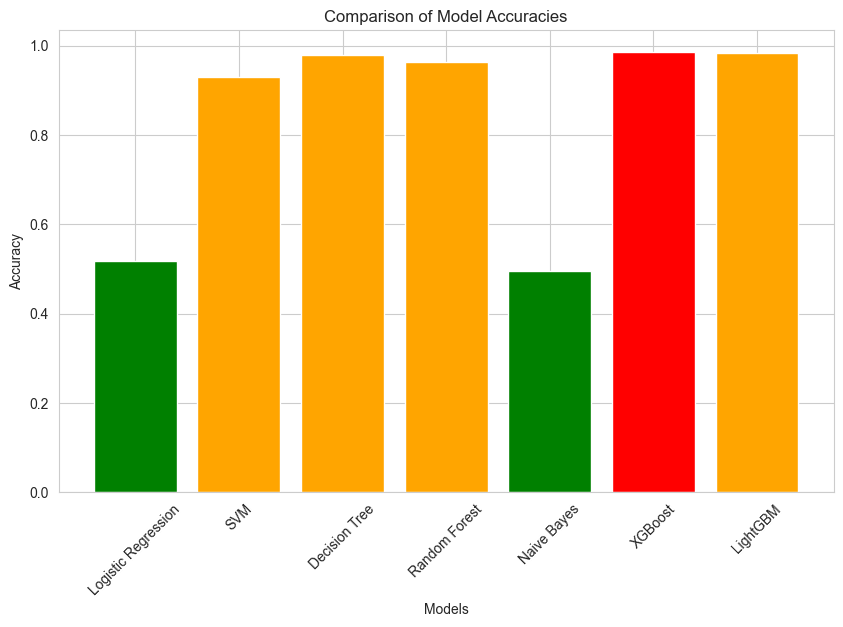

In [8]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# 逻辑回归模型
logreg = LogisticRegression(random_state=42)
logreg.fit(X_train_resampled, y_train_resampled)
y_pred_logreg = logreg.predict(X_test)
accuracy_logreg = accuracy_score(y_test, y_pred_logreg)

# SVM模型
svm = SVC(random_state=42)
svm.fit(X_train_resampled, y_train_resampled)
y_pred_svm = svm.predict(X_test)
accuracy_svm = accuracy_score(y_test, y_pred_svm)

# 决策树模型
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train_resampled, y_train_resampled)
y_pred_dtree = dtree.predict(X_test)
accuracy_dtree = accuracy_score(y_test, y_pred_dtree)

# 随机森林模型
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_resampled, y_train_resampled)
y_pred_rf = rf.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

# 朴素贝叶斯模型
nb = GaussianNB()
nb.fit(X_train_resampled, y_train_resampled)
y_pred_nb = nb.predict(X_test)
accuracy_nb = accuracy_score(y_test, y_pred_nb)

# XGBoost模型
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train_resampled, y_train_resampled)
y_pred_xgb = xgb_model.predict(X_test)
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

# LightGBM模型
lgbm_model = LGBMClassifier(random_state=42)
lgbm_model.fit(X_train_resampled, y_train_resampled)
y_pred_lgbm = lgbm_model.predict(X_test)
accuracy_lgbm = accuracy_score(y_test, y_pred_lgbm)

# 模型名称和对应的准确率
models = ['Logistic Regression', 'SVM', 'Decision Tree', 'Random Forest', 'Naive Bayes', 'XGBoost', 'LightGBM']
accuracies = [accuracy_logreg, accuracy_svm, accuracy_dtree, accuracy_rf, accuracy_nb, accuracy_xgb, accuracy_lgbm]

# 根据准确率设置颜色
colors = []
for acc in accuracies:
    if acc < 0.6:
        colors.append('green')
    elif 0.6 <= acc < 0.8:
        colors.append('yellowgreen')
    elif 0.8 <= acc < 0.9:
        colors.append('yellow')
    else:
        colors.append('orange')
# 确定最优模型索引
max_index = accuracies.index(max(accuracies))

# 高亮标注表现最佳的模型
colors[max_index] = 'red'
# 可视化
sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))
plt.bar(models, accuracies, color=colors)
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Comparison of Model Accuracies')
plt.xticks(rotation=45)
plt.show()

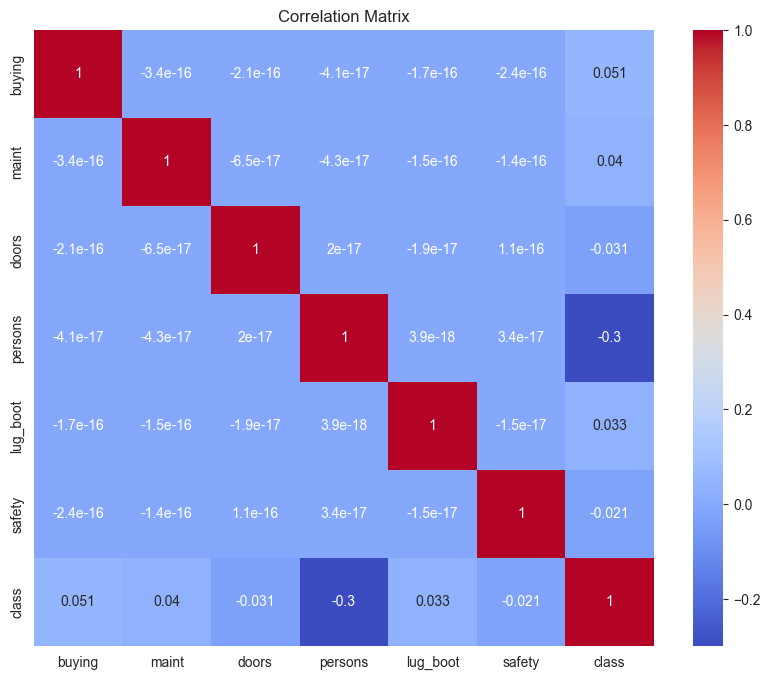

特征 buying 与 class 的卡方统计量: 189.24300964187327, p值: 5.9280625992133936e-36
特征 maint 与 class 的卡方统计量: 142.9405303030303, p值: 2.5476519845077733e-26
特征 doors 与 class 的卡方统计量: 10.384780190165564, p值: 0.32024215990030563
特征 persons 与 class 的卡方统计量: 371.3367281433981, p值: 4.039968047270742e-77
特征 lug_boot 与 class 的卡方统计量: 53.28202539802095, p值: 1.0294402753134833e-09
特征 safety 与 class 的卡方统计量: 479.3224398131512, p值: 2.3891553990440347e-100


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

# 读取数据
column_names = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
data = pd.read_csv('car.data', names=column_names, sep=',')

# 对所有特征和目标变量进行标签编码
label_encoders = {}
for col in data.columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# 提取特征和目标变量
X = data.drop('class', axis=1)
y = data['class']

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 过采样处理数据不平衡问题
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# 创建并训练 XGBoost 模型
xgb_model = xgb.XGBClassifier(random_state=42)
xgb_model.fit(X_train_resampled, y_train_resampled)

# 初始化 SHAP 解释器
explainer = shap.Explainer(xgb_model)
# 计算测试集的 SHAP 值
shap_values = explainer(X_test)

# 绘制所有特征的部分依赖图
# 相关性分析
correlation_matrix = data.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

for col in X.columns:
    cross_tab = pd.crosstab(data[col], data['class'])
    chi2, p, dof, expected = chi2_contingency(cross_tab)
    print(f"特征 {col} 与 class 的卡方统计量: {chi2}, p值: {p}")

In [42]:
这个错误 `TypeError: cannot unpack non-iterable NoneType object` 是因为 `shap.summary_plot` 函数并不返回一个包含 `fig` 和 `ax` 的元组（即它返回 `None`），但你在代码中尝试对其返回值进行解包操作（`fig, ax = shap.summary_plot(...)`），这就导致了错误。

`shap.summary_plot` 函数的主要作用是绘制图形并显示，而不是返回图形对象。如果你想要获取图形的 `Figure` 和 `Axes` 对象以便进行进一步的自定义操作，可以使用 `matplotlib` 的标准方式来创建图形，然后将 `ax` 对象传递给 `shap.summary_plot` 函数。

以下是修改后的代码：

```python
import shap
import xgboost as xgb
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

# 读取数据
column_names = ['buying','maint', 'doors', 'persons', 'lug_boot','safety', 'class']
data = pd.read_csv('car.data', names=column_names, sep=',')

# 对所有特征和目标变量进行标签编码
label_encoders = {}
for col in data.columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# 提取特征和目标变量
X = data.drop('class', axis=1)
y = data['class']

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 使用最佳参数重新训练一个新的 XGBoost 模型
best_params = {
    'learning_rate': 0.1,
    'n_estimators': 200,
   'max_depth': 6,
   'subsample': 0.8,
    'colsample_bytree': 0.8
}
xgb_best = xgb.XGBClassifier(**best_params)
xgb_best.fit(X_train, y_train)

# 使用 shap 进行解释
# 创建一个 SHAP 解释器，使用训练好的 XGBoost 模型
explainer = shap.Explainer(xgb_best)

# 计算 SHAP 值，使用训练集
shap_values = explainer(X_train)

# 定义一个函数来根据横坐标的值划分颜色
def get_color_by_xaxis(x_value):
    if x_value > 1.5:
        return'red'
    elif 1.0 <= x_value <= 1.5:
        return 'orange'
    elif 0.5 <= x_value < 1.0:
        return 'yellow'
    else:
        return 'green'

# 可视化所有类别的 SHAP 汇总图
# 多分类 SHAP 值解析与处理
if len(xgb_best.classes_) > 2:
    # 多分类问题
    for i, class_name in enumerate(xgb_best.classes_):
        class_shap_values = shap_values.values[:, :, i]
        # 计算每个特征的平均 SHAP 值绝对值（即横坐标的值）
        mean_shap_values = np.abs(class_shap_values).mean(axis=0)

        # 根据横坐标的值获取颜色列表
        colors = [get_color_by_xaxis(val) for val in mean_shap_values]

        # 创建图形和轴对象
        fig, ax = plt.subplots()
        shap.summary_plot(class_shap_values, X_train,
                          feature_names=X_train.columns,
                          plot_type="bar",
                          color=colors,
                          title=f"SHAP Summary Plot for Class {class_name}",
                          ax=ax)
        plt.show()
else:
    # 二分类问题
    # 计算每个特征的平均 SHAP 值绝对值（即横坐标的值）
    mean_shap_values = np.abs(shap_values.values).mean(axis=0)

    # 根据横坐标的值获取颜色列表
    colors = [get_color_by_xaxis(val) for val in mean_shap_values]

    # 创建图形和轴对象
    fig, ax = plt.subplots()
    shap.summary_plot(shap_values.values, X_train,
                      feature_names=X_train.columns,
                      plot_type="bar",
                      color=colors,
                      title="SHAP Summary Plot",
                      ax=ax)
    plt.show()
```

在这个修改后的代码中，使用 `plt.subplots()` 来创建 `Figure` 和 `Axes` 对象，然后将 `ax` 对象传递给 `shap.summary_plot` 函数，这样就避免了尝试解包 `None` 对象的错误。 

SyntaxError: invalid syntax (2156082302.py, line 1)